# Proyek Analisis Data: Bike Sharing Dataset

- **Nama:** Ikfi Ardani Kharisma
- **Email:** ikfiardanikharisma@gmail.com
- **ID Dicoding:** ds284b6x0777

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa saja puncak rata-rata penyewaan sepeda per jam terjadi pada hari kerja dibandingkan akhir pekan selama periode 2011–2012, dan berapa selisih rata-rata penyewaannya pada jam-jam puncak tersebut, sehingga operator dapat menentukan jam penempatan dan redistribusi sepeda?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata total penyewaan sepeda harian pada setiap kondisi cuaca (`weathersit`) dan musim (`season`) selama periode 2011–2012, sehingga operator dapat merencanakan promosi dan jumlah armada sepeda untuk setiap musim?


## Import Semua Packages/Library yang Digunakan

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load day_df

In [16]:
day_df = pd.read_csv("day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour_df

In [17]:
hour_df = pd.read_csv("hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- `day_df` berisi data agregat harian (731 baris, 16 kolom), sedangkan `hour_df` berisi data per jam (17.379 baris, 17 kolom). Perbedaan satu-satunya adalah kolom `hr` (jam) yang hanya ada di `hour_df`.
- Kedua tabel mencakup 2 tahun penuh (2011–2012) dari sistem Capital Bikeshare, Washington D.C., sehingga cocok untuk menjawab kedua pertanyaan bisnis: `hour_df` untuk pola per jam (Pertanyaan 1) dan `day_df` untuk pengaruh cuaca dan musim (Pertanyaan 2).

### Assessing Data

###Identifying data type and missing value problem

In [18]:
day_df.info()
hour_df.info()
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat day_df :", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

### Identifying incomplete hourly data probleb

In [19]:
print("Jumlah baris hour_df         :", len(hour_df))
print("Jumlah ideal (731 hari x 24) :", day_df["dteday"].nunique() * 24)

Jumlah baris hour_df         : 17379
Jumlah ideal (731 hari x 24) : 17544


**Steps to Take:**
- Kolom `dteday` pada `day_df` dan `hour_df` bertipe `object` (string), sehingga harus diubah ke tipe `datetime`.
- `hour_df` hanya memiliki 17.379 baris dari 17.544 yang seharusnya (731 hari x 24 jam), artinya ada 165 jam yang tidak tercatat. Nilai `cnt` terkecil di `hour_df` adalah 1 (tidak ada baris dengan `cnt` = 0), sehingga jam-jam tersebut hampir pasti jam tanpa penyewaan yang tidak dicatat. Perbaikannya: buat kalender lengkap 731 hari x 24 jam, lalu isi `casual`, `registered`, dan `cnt` pada jam yang hilang dengan 0.


**Insight:**
- Tidak ada missing value maupun data duplikat pada `day_df` dan `hour_df`.
- Masalah yang ditemukan adalah tipe data `dteday` yang belum sesuai dan 165 jam yang tidak tercatat di `hour_df`.

### Cleaning Data

In [20]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[ns] datetime64[ns]


###Fixing incomplete hourly data problem

In [21]:
# 1. Buat kalender lengkap 731 hari x 24 jam
kalender = pd.MultiIndex.from_product(
    [sorted(hour_df["dteday"].unique()), range(24)], names=["dteday", "hr"]
).to_frame(index=False)

# 2. Gabungkan dengan data asli, jam yang tidak tercatat diisi 0 penyewaan
hour_df = kalender.merge(hour_df, on=["dteday", "hr"], how="left")
for kolom in ["casual", "registered", "cnt"]:
    hour_df[kolom] = hour_df[kolom].fillna(0).astype(int)

# 3. Lengkapi atribut tingkat hari (musim, hari kerja, dll.) dari day_df untuk jam yang baru ditambahkan
kolom_hari = ["season", "yr", "mnth", "holiday", "weekday", "workingday"]
hour_df = hour_df.drop(columns=kolom_hari).merge(day_df[["dteday"] + kolom_hari], on="dteday")

print("Jumlah baris hour_df sekarang:", len(hour_df))
print("Total cnt harian hour_df sama dengan day_df:", hour_df.groupby("dteday")["cnt"].sum().eq(day_df.set_index("dteday")["cnt"]).all())

Jumlah baris hour_df sekarang: 17544
Total cnt harian hour_df sama dengan day_df: True


**Insight:**
- Tipe data `dteday` pada `day_df` dan `hour_df` sudah menjadi `datetime`.
- `hour_df` sekarang lengkap, yaitu 17.544 baris (731 hari x 24 jam). Total `cnt` harian pada `hour_df` sama persis dengan `day_df`, sehingga kedua tabel konsisten.

## Exploratory Data Analysis (EDA)

###Explore pola penyewaan per jam: hari kerja vs akhir pekan/libur

In [22]:
hour_df["tipe_hari"] = hour_df["workingday"].map({1: "Hari Kerja", 0: "Akhir Pekan/Libur"})

pola_jam = hour_df.groupby(["hr", "tipe_hari"])["cnt"].mean().unstack().round(1)
print(pola_jam)
print("\nJam puncak:")
print(pola_jam.idxmax())
print("\nNilai puncak:")
print(pola_jam.max())

# Rasio hari kerja terhadap akhir pekan/libur pada jam-jam kunci
jam_kunci = pola_jam.loc[[8, 13, 17]].copy()
jam_kunci["rasio_kerja_vs_libur"] = (jam_kunci["Hari Kerja"] / jam_kunci["Akhir Pekan/Libur"]).round(2)
jam_kunci

tipe_hari  Akhir Pekan/Libur  Hari Kerja
hr                                      
0                       90.4        36.5
1                       69.2        16.4
2                       52.5         8.5
3                       25.3         4.6
4                        8.1         5.1
5                        8.4        24.7
6                       18.6       101.7
7                       43.4       288.3
8                      105.7       473.2
9                      171.6       239.6
10                     255.9       134.3
11                     315.3       157.0
12                     366.3       199.6
13                     372.7       197.6
14                     364.6       182.8
15                     358.8       200.5
16                     352.7       292.5
17                     323.5       524.2
18                     279.8       490.3
19                     230.7       347.0
20                     174.0       248.7
21                     141.4       185.5
22              

tipe_hari,Akhir Pekan/Libur,Hari Kerja,rasio_kerja_vs_libur
hr,,,
8,105.7,473.2,4.48
13,372.7,197.6,0.53
17,323.5,524.2,1.62


### Explore pengaruh cuaca dan musim terhadap penyewaan harian

In [23]:
day_df["cuaca"] = day_df["weathersit"].map({1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan"})
day_df["musim"] = day_df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})

print(day_df.groupby("cuaca")["cnt"].agg(["count", "mean", "median"]).round(0))
print()
print(day_df.groupby("musim")["cnt"].agg(["count", "mean", "median"]).round(0))
print()
print(day_df.pivot_table(index="musim", columns="cuaca", values="cnt", aggfunc="mean").round(0))

                    count    mean  median
cuaca                                    
Berkabut/Berawan      247  4036.0  4040.0
Cerah                 463  4877.0  4844.0
Hujan/Salju Ringan     21  1803.0  1817.0

        count    mean  median
musim                        
Fall      188  5644.0  5354.0
Spring    181  2604.0  2209.0
Summer    184  4992.0  4942.0
Winter    178  4728.0  4634.0

cuaca   Berkabut/Berawan   Cerah  Hujan/Salju Ringan
musim                                               
Fall              5222.0  5878.0              2752.0
Spring            2357.0  2811.0               935.0
Summer            4237.0  5549.0              1169.0
Winter            4654.0  5044.0              1962.0


## Visualization & Explanatory Analysis

### Pertanyaan 1:

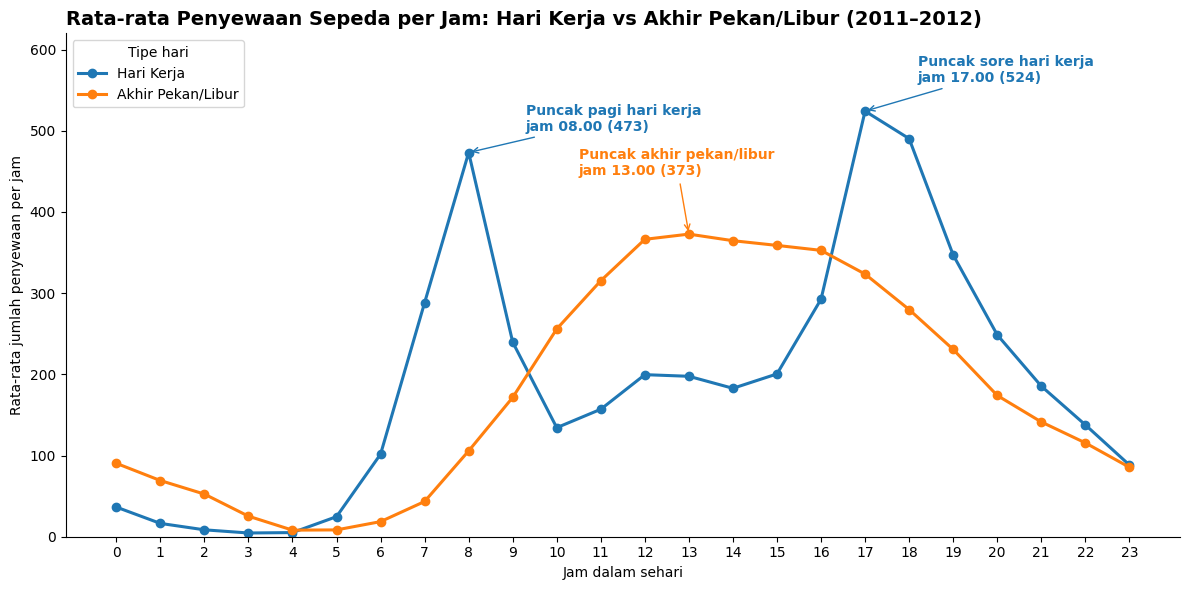

In [24]:
warna = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}

fig, ax = plt.subplots(figsize=(12, 6))
for tipe in ["Hari Kerja", "Akhir Pekan/Libur"]:
    ax.plot(pola_jam.index, pola_jam[tipe], marker="o", linewidth=2.2, color=warna[tipe], label=tipe)

ax.annotate("Puncak pagi hari kerja\njam 08.00 (473)", xy=(8, pola_jam.loc[8, "Hari Kerja"]),
            xytext=(9.3, 500), arrowprops=dict(arrowstyle="->", color=warna["Hari Kerja"]),
            color=warna["Hari Kerja"], fontsize=10, fontweight="bold")
ax.annotate("Puncak sore hari kerja\njam 17.00 (524)", xy=(17, pola_jam.loc[17, "Hari Kerja"]),
            xytext=(18.2, 560), arrowprops=dict(arrowstyle="->", color=warna["Hari Kerja"]),
            color=warna["Hari Kerja"], fontsize=10, fontweight="bold")
ax.annotate("Puncak akhir pekan/libur\njam 13.00 (373)", xy=(13, pola_jam.loc[13, "Akhir Pekan/Libur"]),
            xytext=(10.5, 445), arrowprops=dict(arrowstyle="->", color=warna["Akhir Pekan/Libur"]),
            color=warna["Akhir Pekan/Libur"], fontsize=10, fontweight="bold")

ax.set_title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2011–2012)", fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata jumlah penyewaan per jam")
ax.set_xticks(range(0, 24))
ax.set_ylim(0, 620)
ax.grid(axis="x", visible=False)
ax.legend(title="Tipe hari", loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2:

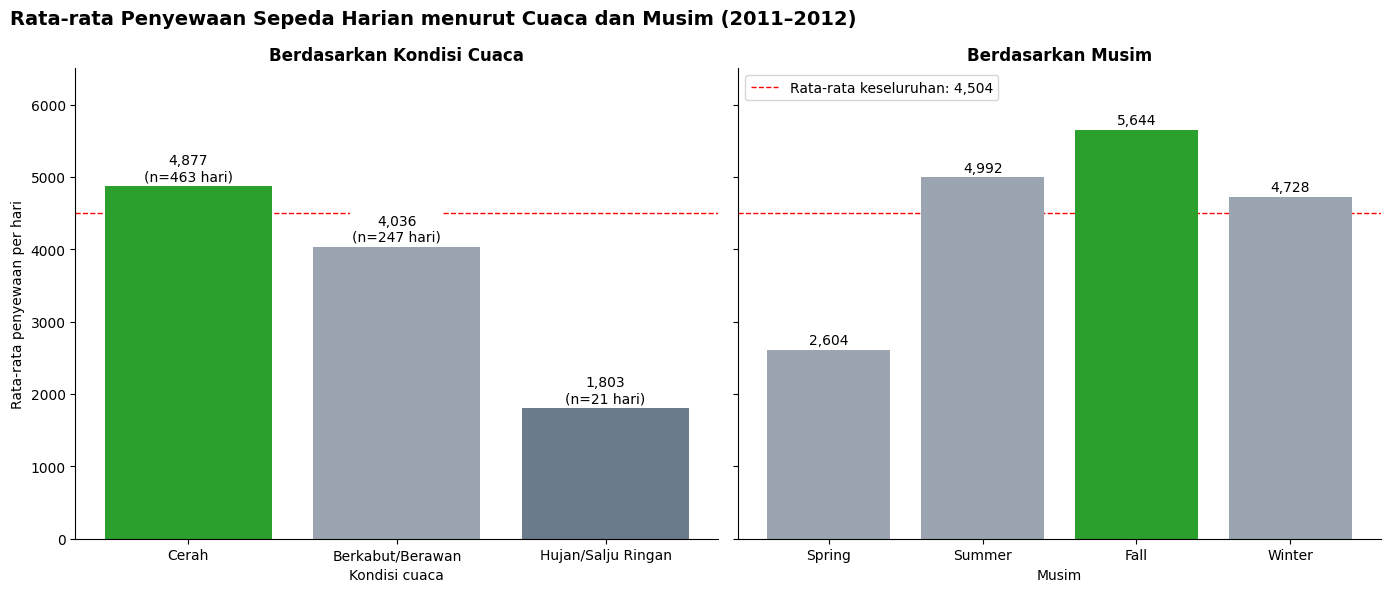

In [25]:
urutan_cuaca = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]
urutan_musim = ["Spring", "Summer", "Fall", "Winter"]
cuaca_stat = day_df.groupby("cuaca")["cnt"].agg(jumlah_hari="count", rata2="mean").loc[urutan_cuaca]
musim_stat = day_df.groupby("musim")["cnt"].agg(jumlah_hari="count", rata2="mean").loc[urutan_musim]
rata_total = day_df["cnt"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

bar1 = axes[0].bar(cuaca_stat.index, cuaca_stat["rata2"], color=["#2ca02c", "#9aa5b1", "#6b7b8c"])
axes[0].set_title("Berdasarkan Kondisi Cuaca", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Rata-rata penyewaan per hari")
for batang, n in zip(bar1, cuaca_stat["jumlah_hari"]):
    axes[0].text(batang.get_x() + batang.get_width() / 2, batang.get_height() + 80,
                 f"{batang.get_height():,.0f}\n(n={int(n)} hari)", ha="center", fontsize=10,
                 bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

tertinggi = musim_stat["rata2"].idxmax()
bar2 = axes[1].bar(musim_stat.index, musim_stat["rata2"],
                   color=["#2ca02c" if m == tertinggi else "#9aa5b1" for m in musim_stat.index])
axes[1].set_title("Berdasarkan Musim", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Musim")
for batang in bar2:
    axes[1].text(batang.get_x() + batang.get_width() / 2, batang.get_height() + 80,
                 f"{batang.get_height():,.0f}", ha="center", fontsize=10,
                 bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

for ax in axes:
    ax.axhline(rata_total, color="red", linestyle="--", linewidth=1, zorder=0, label=f"Rata-rata keseluruhan: {rata_total:,.0f}")
    ax.set_ylim(0, 6500)
    ax.grid(axis="x", visible=False)
axes[1].legend(loc="upper left")

fig.suptitle("Rata-rata Penyewaan Sepeda Harian menurut Cuaca dan Musim (2011–2012)", fontsize=14, fontweight="bold", x=0.01, ha="left")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** Hari kerja punya dua puncak penyewaan, jam 08.00 (rata-rata 473) dan jam 17.00 (rata-rata 524, puncak tertinggi). Akhir pekan/libur punya satu puncak landai jam 13.00 (rata-rata 373). Pada jam 08.00 hari kerja sekitar 4,5 kali lebih ramai, sedangkan pada jam 13.00 akhir pekan/libur sekitar 1,9 kali lebih ramai.
- **Pertanyaan 2:** Dibanding hari cerah (4.877 per hari), hari berkabut/berawan turun sekitar 17% (4.036) dan hari hujan/salju ringan turun sekitar 63% (1.803). Musim Fall tertinggi (5.644), sedangkan Spring terendah (2.604), sekitar 54% di bawah Fall.
- Hari hujan/salju ringan hanya 21 hari, sehingga angkanya kurang stabil dibanding kategori cuaca lain. Label musim mengikuti kode pada dataset (`Readme.txt`).

## Analisis Lanjutan (Opsional)

Analisis lanjutan memakai teknik **manual grouping (binning)** tanpa algoritma machine learning:
1. **Pengelompokan jam menjadi periode waktu** (Dini Hari 00–05, Pagi 06–09, Siang 10–15, Sore 16–19, Malam 20–23) untuk melihat periode mana yang menjadi prioritas penyediaan dan perawatan sepeda pada hari kerja dan akhir pekan/libur.
2. **Pengelompokan hari menjadi kategori permintaan** Rendah (< 3.000 penyewaan), Sedang (3.000–6.000), dan Tinggi (> 6.000), lalu dibandingkan antar musim untuk melihat seberapa sering permintaan rendah atau tinggi terjadi.

tipe_hari          Akhir Pekan/Libur  Hari Kerja
periode                                         
Dini Hari (00-05)               42.3        16.0
Pagi (06-09)                    84.8       275.7
Siang (10-15)                  338.9       178.6
Sore (16-19)                   296.7       413.5
Malam (20-23)                  129.1       165.1


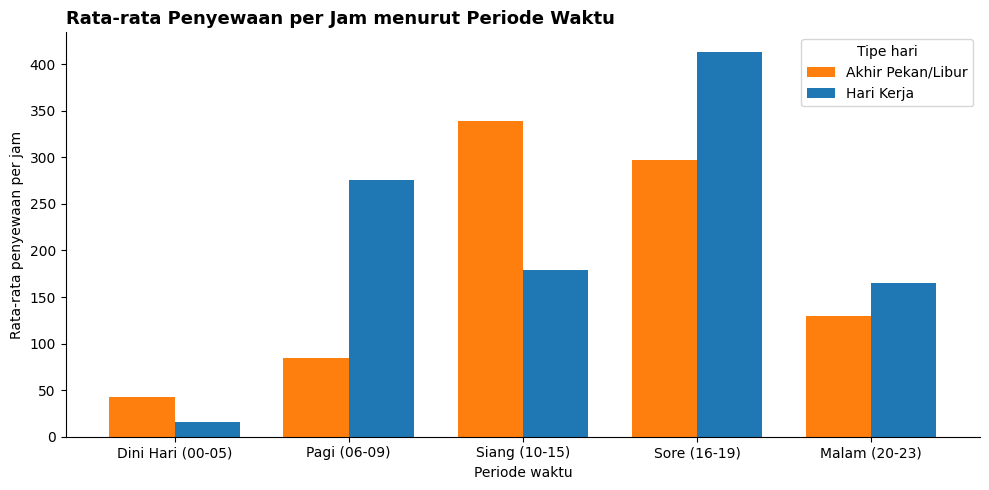

kategori_permintaan
Rendah    172
Sedang    379
Tinggi    180
Name: count, dtype: int64
kategori_permintaan  Rendah  Sedang  Tinggi
musim                                      
Spring                 65.0    33.0     3.0
Summer                 14.0    53.0    34.0
Fall                    2.0    56.0    41.0
Winter                 15.0    66.0    20.0


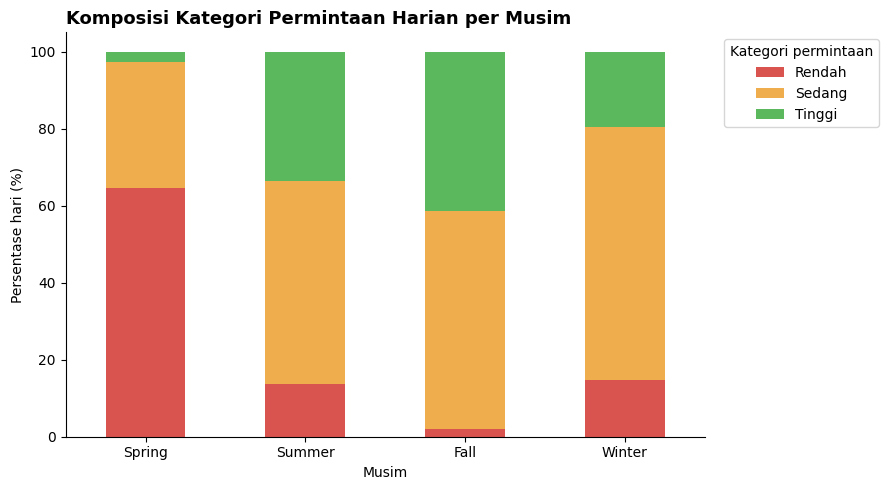

In [26]:
# 1. Manual grouping: periode waktu
hour_df["periode"] = pd.cut(hour_df["hr"], bins=[-1, 5, 9, 15, 19, 23],
                            labels=["Dini Hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"])
periode_stat = hour_df.groupby(["periode", "tipe_hari"], observed=True)["cnt"].mean().unstack().round(1)
print(periode_stat)

periode_stat.plot(kind="bar", figsize=(10, 5), color=[warna["Akhir Pekan/Libur"], warna["Hari Kerja"]], width=0.75)
plt.title("Rata-rata Penyewaan per Jam menurut Periode Waktu", fontsize=13, fontweight="bold", loc="left")
plt.xlabel("Periode waktu")
plt.ylabel("Rata-rata penyewaan per jam")
plt.xticks(rotation=0)
plt.legend(title="Tipe hari")
sns.despine()
plt.tight_layout()
plt.show()

# 2. Manual grouping: kategori permintaan harian
day_df["kategori_permintaan"] = pd.cut(day_df["cnt"], bins=[0, 3000, 6000, 10000], labels=["Rendah", "Sedang", "Tinggi"])
print(day_df["kategori_permintaan"].value_counts().reindex(["Rendah", "Sedang", "Tinggi"]))

komposisi = pd.crosstab(day_df["musim"], day_df["kategori_permintaan"], normalize="index").loc[urutan_musim] * 100
print(komposisi.round(0))

komposisi.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#d9534f", "#f0ad4e", "#5cb85c"])
plt.title("Komposisi Kategori Permintaan Harian per Musim", fontsize=13, fontweight="bold", loc="left")
plt.xlabel("Musim")
plt.ylabel("Persentase hari (%)")
plt.xticks(rotation=0)
plt.legend(title="Kategori permintaan", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- **Periode waktu:** Pada hari kerja, periode Sore (16.00–19.00) adalah yang tersibuk (rata-rata 413,5 per jam), disusul Pagi (275,7). Pada akhir pekan/libur, periode Siang (10.00–15.00) tersibuk (338,9 per jam). Dini hari paling sepi di kedua tipe hari (16,0 pada hari kerja dan 42,3 pada akhir pekan/libur).
- **Kategori permintaan:** dari 731 hari, 172 hari tergolong Rendah, 379 Sedang, dan 180 Tinggi. Musim Spring didominasi hari Rendah (65%) dan hampir tidak punya hari Tinggi (3%), sedangkan Fall punya hari Tinggi terbanyak (41%) dan hampir tanpa hari Rendah (2%).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan berbeda tajam antara hari kerja dan akhir pekan/libur. Hari kerja memiliki dua puncak, jam 08.00 (rata-rata 473 penyewaan) dan jam 17.00 (524, puncak tertinggi). Pada jam 08.00 penyewaan hari kerja sekitar 4,5 kali akhir pekan/libur. Akhir pekan/libur hanya memiliki satu puncak landai pada jam 13.00 (373), yang sekitar 1,9 kali lebih tinggi daripada hari kerja pada jam yang sama. Dini hari (00.00–05.00) paling sepi di kedua tipe hari.
- **Conclusion pertanyaan 2:** Cuaca dan musim sangat memengaruhi penyewaan harian. Dibanding hari cerah (rata-rata 4.877 per hari), hari berkabut/berawan turun sekitar 17% (4.036) dan hari hujan/salju ringan turun sekitar 63% (1.803). Musim Fall tertinggi (5.644 per hari) dan Spring terendah (2.604), sekitar 54% di bawah Fall. Urutan Cerah > Berkabut/Berawan > Hujan/Salju Ringan berlaku di setiap musim. Perlu diingat jumlah hari hujan/salju ringan hanya 21 hari.

**Rekomendasi Action Item:**
- **Distribusi sepeda hari kerja:** pastikan sepeda sudah tersedia dan redistribusi selesai sebelum jam 07.00 dan sebelum jam 16.00, menyambut puncak pagi dan sore. Hindari kegiatan redistribusi berat pada 07.00–09.00 dan 16.00–19.00.
- **Penjadwalan perawatan:** lakukan pengecekan dan servis sepeda pada periode permintaan terendah, yaitu dini hari (00.00–05.00) dan siang pada hari kerja (10.00–15.00).
- **Akhir pekan/libur:** tingkatkan ketersediaan sepeda pada 10.00–15.00, karena ini periode tersibuk pada tipe hari tersebut.
- **Perencanaan armada per musim:** siapkan armada maksimum pada Fall dan Summer, jadwalkan perawatan besar pada musim dengan permintaan terendah (Spring), dan pertimbangkan promosi untuk mendorong penggunaan pada musim tersebut.
- **Respons cuaca:** pantau prakiraan cuaca harian. Saat hujan/salju kurangi armada yang disebar, sedangkan pada hari berkabut/berawan permintaan masih sekitar 83% dari hari cerah sehingga operasional bisa berjalan normal.